# Políticas y semáforos: los umbrales son política, nunca regulación

**Pregunta:** Un valor p es un hecho de los datos y un semáforo es una lectura de él. En dos muestras cuya verdad conocemos, ¿la política por defecto del motor encuentra la que está mal y deja en paz a la correcta, y qué ocurre con el color cuando solo cambia la política?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** notebook 02 de este tema (un primer TestResult)
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- leer la `Policy` por defecto del motor y decir qué significa cada tipo de umbral;
- clasificar un valor p o una métrica en un semáforo con `Threshold.classify` y dibujar las zonas que recorta un umbral;
- mostrar que una política más estricta y una más laxa dejan intactos el estadístico y el valor p y cambian solo el color;
- explicar por qué Contraste redacta cada semáforo como una lectura bajo una política con nombre, y dónde una regulación fija ella misma las zonas.

## Preparación

Instala el entorno fijado una vez, en un entorno virtual, con el comando habitual:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2 pandas==3.0.6
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Imprime la versión de cada paquete que usa este notebook, para compararla con notebooks/requirements.txt
import csv
import importlib.metadata as md
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from riskvalidation.core.policy import Policy, Threshold, default_policy, policy_from_mapping
from riskvalidation.validation.calibration import pd_jeffreys
from riskvalidation.validation.market import basel_traffic_light

for name in ("riskvalidation", "numpy", "matplotlib", "pandas"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2
pandas 3.0.6


## Datos

Dos muestras puntuadas con una **verdad conocida**, confirmadas en `data/examples/` como los ejemplos de la guía para traer tu propio modelo (`docs/guides/02_validate-your-own-model.md`). Ambas son sintéticas: el proceso fuera de línea las genera a partir de una semilla (`data-pipeline/pipeline/io/examples.py`), de modo que no interviene ningún conjunto de datos de terceros ni su licencia, y las cubre la licencia MIT del repositorio.

- `scored_sample_development.csv`: 2.000 deudores observados el 2024-12-31 cuyas PD están calibradas por construcción, porque cada incumplimiento es una extracción de Bernoulli con su propia PD.
- `scored_sample_current.csv`: 2.000 deudores observados el 2025-12-31 de una población más riesgosa, cuyos incumplimientos llegan a 1,5 veces la PD. El ordenamiento está intacto y el nivel está subestimado en un tercio.
- Columnas: `id,observation_date,target,pd,segment`, donde `target` vale 1 si hubo incumplimiento en el horizonte.

Conocer la verdad permite hacer una pregunta justa a una política: ¿encuentra la muestra que está mal y deja en paz a la correcta? La celda siguiente define un pequeño lector de los dos archivos, con la biblioteca estándar, y los carga.

In [2]:
# Lee las dos muestras confirmadas con la biblioteca estándar: el desenlace y la PD de cada deudor
ROOT = Path("../../..").resolve()
EXAMPLES = ROOT / "data" / "examples"


def read_sample(name):
    with open(EXAMPLES / f"scored_sample_{name}.csv", newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    return np.array([int(r["target"]) for r in rows]), np.array([float(r["pd"]) for r in rows])


samples = {name: read_sample(name) for name in ("development", "current")}

## Método

Una política es la parte de una validación que es una decisión, y el motor la mantiene aparte de las pruebas a propósito. Primero vemos cuál es la verdad en las dos muestras; luego abrimos la política, clasificamos valores a mano, ejecutamos una prueba bajo tres políticas, escribimos una política como archivo y terminamos con la única familia de pruebas cuyas zonas define una regulación.

### Paso 1: cuál es la verdad

La celda siguiente cuenta, para cada muestra, los incumplimientos que contiene y los incumplimientos que esperan sus propias PD, y dibuja los dos números lado a lado. Una política justa debería objetar solo donde los dos discrepan.

muestra de desarrollo: deudores: 2000
    incumplimientos: 100 | esperados por las PD: 111.2
muestra actual: deudores: 2000
    incumplimientos: 207 | esperados por las PD: 138.1


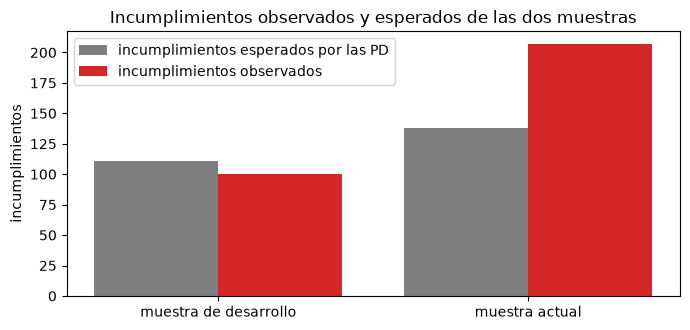

In [3]:
# Cuenta los incumplimientos de cada muestra y los que esperan sus propias PD, y los dibuja lado a lado
NAMES = {"development": "muestra de desarrollo", "current": "muestra actual"}
observed = [int(y.sum()) for y, _ in samples.values()]
expected = [float(pd_hat.sum()) for _, pd_hat in samples.values()]
for name, (y, pd_hat) in samples.items():
    print(f"{NAMES[name]}: deudores: {len(y)}")
    print(f"    incumplimientos: {int(y.sum())} | esperados por las PD: {pd_hat.sum():.1f}")

positions = np.arange(len(samples))
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(positions - 0.2, expected, width=0.4, label="incumplimientos esperados por las PD", color="tab:gray")
ax.bar(positions + 0.2, observed, width=0.4, label="incumplimientos observados", color="tab:red")
ax.set_xticks(positions)
ax.set_xticklabels([NAMES[name] for name in samples])
ax.set_ylabel("incumplimientos")
ax.set_title("Incumplimientos observados y esperados de las dos muestras")
ax.legend()
fig.tight_layout()
plt.show()

La muestra de desarrollo contiene 100 incumplimientos donde sus PD esperan 111,2, algo menos de lo esperado y bien dentro de lo que da el azar. La muestra actual contiene 207 donde sus PD esperan 138,1, la mitad más, que es exactamente el factor 1,5 de su construcción. La figura muestra la verdad con claridad, pero un validador nunca tiene la verdad: solo tiene el valor p de una prueba y una regla que lo convierte en un color. Esa regla es la política.

### Paso 2: la política empaquetada

Una `Policy` es una tabla con nombre y versión de umbrales indexada por el identificador de una prueba. `default_policy()` carga la que empaqueta el motor. Hay tres tipos de `Threshold`: `p_value` (rojo bajo `red`, ámbar bajo `amber`, verde en otro caso), `upper_bad` (mayor es peor, como el PSI) y `lower_bad` (menor es peor, como un AUC). La celda siguiente imprime la etiqueta, cuenta los umbrales por tipo y lee el umbral de cinco pruebas que usa el tema.

In [4]:
# Abre la política empaquetada: su etiqueta, sus umbrales por tipo y el umbral de cinco pruebas
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "sin evaluar"}
policy = default_policy()
print("política:", policy.label)
print("umbrales por tipo:", dict(Counter(t.kind for t in policy.thresholds.values())))
rows = []
for test_id in ("pd.jeffreys", "pd.binomial", "stability.psi", "disc.auc_vs_initial", "disc.auc"):
    cut = policy.threshold(test_id)
    rows.append({"prueba": test_id, "tipo": "ninguno" if cut is None else cut.kind,
                 "ámbar": None if cut is None else cut.amber, "rojo": None if cut is None else cut.red})
pd.DataFrame(rows)

política: riskvalidation-default 2026.10.1
umbrales por tipo: {'p_value': 25, 'upper_bad': 20, 'lower_bad': 3}


,prueba,tipo,ámbar,rojo
0,pd.jeffreys,p_value,0.05,0.01
1,pd.binomial,p_value,0.05,0.01
2,stability.psi,p_value,0.05,0.01
3,disc.auc_vs_initial,p_value,0.05,0.01
4,disc.auc,ninguno,NaN,NaN


La política por defecto, `riskvalidation-default 2026.10.1`, tiene 48 umbrales: 25 de tipo `p_value`, 20 de tipo `upper_bad` y 3 de tipo `lower_bad`. Las cuatro pruebas de la tabla que llevan umbral usan el mismo par de puntos de corte, 0,05 para ámbar y 0,01 para rojo, que son los niveles de significancia convencionales de 5 por ciento y 1 por ciento. `disc.auc` no tiene ningún umbral, así que un resultado suyo nunca puede colorearse; como mostró el notebook 02, vuelve `sin evaluar`. Las instrucciones del BCE (2019) que definen estas pruebas no fijan ningún umbral de aprobación o fallo, y la nota de fuente de cada umbral en el motor lo dice.

### Paso 3: clasificar a mano

`Threshold.classify` es la regla completa: un umbral se construye con un tipo y dos puntos de corte, y asigna un semáforo a un valor. La celda siguiente construye un umbral de cada tipo, con puntos de corte inventados para la ilustración, y clasifica seis valores, el último de ellos un valor ausente.

In [5]:
# Construye un umbral de cada tipo y clasifica algunos valores: la regla completa es Threshold.classify
cuts = {
    "p_value": Threshold(kind="p_value", amber=0.05, red=0.01),
    "upper_bad": Threshold(kind="upper_bad", amber=0.10, red=0.25),
    "lower_bad": Threshold(kind="lower_bad", amber=0.60, red=0.50),
}
tried = [("p_value", 0.20), ("p_value", 0.03), ("p_value", 0.004)]
tried += [("upper_bad", 0.12), ("lower_bad", 0.55), ("lower_bad", None)]
lights = [LIGHT[cuts[kind].classify(value).value] for kind, value in tried]
table = pd.DataFrame(tried, columns=["tipo", "valor"])
table["semáforo"] = lights
table

,tipo,valor,semáforo
0,p_value,0.200,verde
1,p_value,0.030,ámbar
2,p_value,0.004,rojo
3,upper_bad,0.120,ámbar
4,lower_bad,0.550,ámbar
5,lower_bad,NaN,sin evaluar


Las tres primeras filas muestran la regla: un valor p de 0,20 es verde, 0,03 es ámbar y 0,004 es rojo. El valor 0,12 de `upper_bad` es ámbar porque está en 0,10 o por encima y bajo 0,25, y el valor 0,55 de `lower_bad` es ámbar porque está en 0,60 o por debajo y sobre 0,50. Un valor ausente es `sin evaluar`, nunca un verde silencioso. Los umbrales del segundo y del tercer tipo son ilustraciones, no recomendaciones.

### Paso 4: las zonas, dibujadas

La misma regla sobre todo un rango de valores se ve mejor. La celda siguiente pide a cada umbral el semáforo de 300 valores y dibuja la respuesta como una franja de colores.

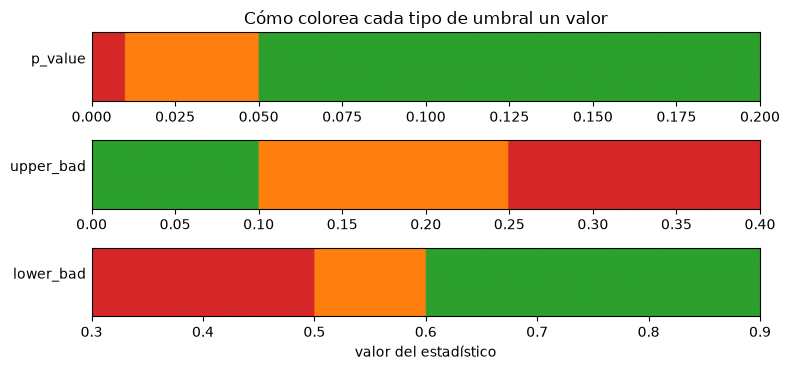

In [6]:
# Colorea una malla de valores con cada umbral, para ver las zonas que recorta la regla
codes = {"green": 0, "amber": 1, "red": 2}
colours = ListedColormap(["tab:green", "tab:orange", "tab:red"])
ranges = {"p_value": (0, 0.2), "upper_bad": (0, 0.4), "lower_bad": (0.3, 0.9)}
fig, axes = plt.subplots(3, 1, figsize=(8, 3.8))
for ax, (kind, cut) in zip(axes, cuts.items()):
    low, high = ranges[kind]
    grid = np.linspace(low, high, 300)
    strip = [[codes[cut.classify(value).value] for value in grid]]
    ax.imshow(strip, aspect="auto", extent=(low, high, 0, 1), cmap=colours, vmin=0, vmax=2)
    ax.set_yticks([])
    ax.set_ylabel(kind, rotation=0, ha="right")
axes[0].set_title("Cómo colorea cada tipo de umbral un valor")
axes[-1].set_xlabel("valor del estadístico")
fig.tight_layout()
plt.show()

Cada franja es un umbral. En la franja `p_value` el rojo ocupa la banda angosta bajo 0,01 y el ámbar la banda hasta 0,05, y todo lo que está encima es verde: un valor p pequeño es la dirección mala. La franja `upper_bad` es verde a la izquierda y pasa a ámbar en 0,10 y a rojo en 0,25: un valor grande es la dirección mala. La franja `lower_bad` es la imagen en espejo. La figura muestra que los tres tipos son una sola idea con la dirección mala cambiada; no dice dónde deben estar los puntos de corte, algo que ninguna figura puede decir.

### Paso 5: una prueba, dos muestras, la política por defecto

Ahora el motor. `pd_jeffreys` recibe el número de deudores, el número de incumplimientos y la PD aplicada, aquí la PD media de la muestra, y aplica la política que se le da. La celda siguiente la ejecuta sobre las dos muestras con la política por defecto, como hizo el notebook 02 con 50 tarjetas.

In [7]:
# Ejecuta la prueba de Jeffreys en ambas muestras con la política por defecto
jeffreys = {}
for name, (y, pd_hat) in samples.items():
    args = dict(n=len(y), d=int(y.sum()), pd=float(pd_hat.mean()))
    jeffreys[name] = pd_jeffreys(**args, policy=policy, model_id=name, segment="portfolio")
table = pd.DataFrame(
    {
        "muestra": [NAMES[name] for name in samples],
        "incumplimientos": observed,
        "esperados": [round(e, 1) for e in expected],
        "valor p": [f"{result.p_value:.3e}" for result in jeffreys.values()],
        "semáforo": [LIGHT[result.light.value] for result in jeffreys.values()],
    }
)
table

,muestra,incumplimientos,esperados,valor p,semáforo
0,muestra de desarrollo,100,111.2,8.629e-01,verde
1,muestra actual,207,138.1,6.047e-09,rojo


La política por defecto encuentra la verdad. La muestra de desarrollo, calibrada por construcción, tiene un valor p de 8.629e-01 y es verde, de modo que la prueba no ve señal de que sus PD sean demasiado bajas. La muestra actual, con 207 incumplimientos frente a 138,1 esperados, tiene un valor p de 6.047e-09 y es roja. Con 2.000 deudores por muestra la prueba tiene potencia para ver un déficit de un tercio en el nivel y la muestra correcta queda en paz, que es lo que le pedimos. Este resultado depende de la política: el paso siguiente cambia la política y mantiene todo lo demás.

### Paso 6: el mismo valor p, otra política

Una política son datos, así que una institución puede tener una más estricta o una más laxa. La celda siguiente construye dos políticas para esta prueba, como objetos `Policy` de un `Threshold` cada uno: `strict-demo` pasa a ámbar bajo 0,90 y a rojo bajo 0,50, y `lenient-demo` pasa a ámbar bajo 1e-6 y a rojo bajo 1e-9. Ambas son ilustraciones. Luego la prueba se ejecuta sobre los mismos arreglos bajo las tres políticas.

In [8]:
# Construye una política más estricta y una más laxa para la misma prueba y lee ambas muestras con las tres
strict = Policy(
    policy_id="strict-demo",
    version="1",
    description="ilustración: una lectura más estricta de una prueba",
    thresholds={"pd.jeffreys": Threshold(kind="p_value", amber=0.90, red=0.50)},
)
lenient = Policy(
    policy_id="lenient-demo",
    version="1",
    description="ilustración: una lectura más laxa de una prueba",
    thresholds={"pd.jeffreys": Threshold(kind="p_value", amber=1e-6, red=1e-9)},
)
policies = {"política por defecto": policy, "strict-demo": strict, "lenient-demo": lenient}
rows = []
for name, (y, pd_hat) in samples.items():
    args = dict(n=len(y), d=int(y.sum()), pd=float(pd_hat.mean()))
    for label, in_use in policies.items():
        result = pd_jeffreys(**args, policy=in_use, model_id=name, segment="portfolio")
        rows.append({"muestra": NAMES[name], "política": label, "valor p": f"{result.p_value:.3e}",
                     "semáforo": LIGHT[result.light.value]})
pd.DataFrame(rows)

,muestra,política,valor p,semáforo
0,muestra de desarrollo,política por defecto,8.629e-01,verde
1,muestra de desarrollo,strict-demo,8.629e-01,ámbar
2,muestra de desarrollo,lenient-demo,8.629e-01,verde
3,muestra actual,política por defecto,6.047e-09,rojo
4,muestra actual,strict-demo,6.047e-09,rojo
5,muestra actual,lenient-demo,6.047e-09,ámbar


La columna del valor p no cambia de una política a otra; cambia solo el semáforo. Bajo `strict-demo` la muestra de desarrollo calibrada pasa a ámbar sin ningún cambio en los datos, y bajo `lenient-demo` la muestra actual, que es roja con la política por defecto, pasa a ámbar porque su valor p está bajo 1e-6 pero no bajo 1e-9. El estadístico no se movió, la muestra no se movió y el color se movió dos veces. Por eso un `TestResult` registra la etiqueta de la política que lo coloreó y los dos puntos de corte: el semáforo siempre puede leerse de nuevo bajo otra política sin ejecutar la prueba.

### Paso 7: los semáforos, dibujados

La celda siguiente pone los dos valores p en un eje logarítmico y dibuja los puntos de corte de las tres políticas como líneas verticales: un punto a la izquierda de una línea está bajo ese umbral.

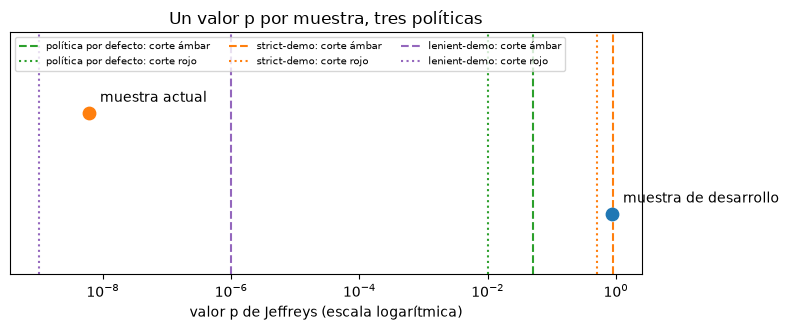

In [9]:
# Dibuja los dos valores p frente a los puntos de corte de las tres políticas
fig, ax = plt.subplots(figsize=(8, 3.4))
for row, name in enumerate(samples):
    p_value = jeffreys[name].p_value
    ax.scatter([p_value], [row], s=80, zorder=3)
    ax.annotate(NAMES[name], (p_value, row), textcoords="offset points", xytext=(8, 8))
styles = (
    ("política por defecto", policy, "tab:green"),
    ("strict-demo", strict, "tab:orange"),
    ("lenient-demo", lenient, "tab:purple"),
)
for label, in_use, colour in styles:
    cut = in_use.threshold("pd.jeffreys")
    ax.axvline(cut.amber, color=colour, linestyle="--", label=f"{label}: corte ámbar")
    ax.axvline(cut.red, color=colour, linestyle=":", label=f"{label}: corte rojo")
ax.set_xscale("log")
ax.set_yticks([])
ax.set_ylim(-0.6, 1.8)
ax.set_xlabel("valor p de Jeffreys (escala logarítmica)")
ax.set_title("Un valor p por muestra, tres políticas")
ax.legend(fontsize=7, ncol=3, loc="upper left")
fig.tight_layout()
plt.show()

La muestra de desarrollo queda a la derecha, en 0,863, justo bajo el corte ámbar de 0,90 de la política estricta y sobre su corte rojo de 0,50, de modo que solo la política estricta la ve ámbar; está a la derecha de todos los puntos de corte de las otras dos políticas, así que allí es verde. La muestra actual queda a la izquierda, cerca de 6e-9: está a la izquierda del corte por defecto de 0,01 y del de la política estricta, así que es roja en ellas, y a la izquierda del corte ámbar laxo en 1e-6 pero a la derecha de su corte rojo en 1e-9, así que es ámbar allí. El eje logarítmico abarca nueve órdenes de magnitud; en un eje lineal los puntos de corte de la política por defecto serían indistinguibles de cero. La figura muestra dónde traza una política sus líneas respecto de los datos, y no te dice cuáles líneas son las correctas.

### Paso 8: una política es un archivo versionado

El motor entrega su política por defecto como un archivo JSON, y `policy_from_mapping` construye una política a partir de un mapeo de esa forma (`load_policy` lee el archivo y la llama). La celda siguiente escribe la forma de la política estricta como texto, la lee de vuelta con el motor y comprueba dos cosas de la copia. No se escribe ningún archivo.

In [10]:
# Escribe la forma de un archivo de política como texto, léelo de vuelta con el motor y comprueba que se comporta igual
text = json.dumps(
    {
        "policy_id": "strict-demo",
        "version": "1",
        "description": "ilustración: una lectura más estricta de una prueba",
        "thresholds": {"pd.jeffreys": {"kind": "p_value", "amber": 0.90, "red": 0.50, "source": "ilustración"}},
    },
    indent=2,
    ensure_ascii=False,
)
print(text)
reloaded = policy_from_mapping(json.loads(text))
print("misma etiqueta:", reloaded.label == strict.label)
print("mismo corte ámbar:", reloaded.threshold("pd.jeffreys").amber == strict.threshold("pd.jeffreys").amber)

{
  "policy_id": "strict-demo",
  "version": "1",
  "description": "ilustración: una lectura más estricta de una prueba",
  "thresholds": {
    "pd.jeffreys": {
      "kind": "p_value",
      "amber": 0.9,
      "red": 0.5,
      "source": "ilustración"
    }
  }
}
misma etiqueta: True
mismo corte ámbar: True


El texto es la política completa: un identificador, una versión, una descripción y un umbral con su fuente. El motor la reconstruye con la misma etiqueta y el mismo corte ámbar, de modo que una política puede revisarse, versionarse y aprobarse como archivo, y un resultado puede nombrarla por su etiqueta. Así tiene una institución su propia política: como un documento bajo control de cambios y no como un número enterrado en el código.

### Paso 9: dónde una regulación fija las zonas

Para las pruebas de crédito de este tema ningún texto supervisor fija umbrales. Unas pocas pruebas de otros temas son la excepción, porque la regulación que implementan define sus propias zonas. `basel_traffic_light` asigna la zona del semáforo de contraste retrospectivo de Basilea (MAR32.9, Tabla 1) a partir del número de excepciones de un modelo de valor en riesgo al 99 por ciento en 250 días, y la zona sale de la probabilidad binomial acumulada de ese conteo con la cobertura del propio modelo, $P(X \le k)$ con $X \sim \mathrm{Bin}(250, 0{,}01)$: ámbar donde alcanza por primera vez 95 por ciento y rojo en 99,99 por ciento. La celda siguiente ejecuta la prueba para 0 a 12 excepciones y dibuja la probabilidad acumulada coloreada por zona.

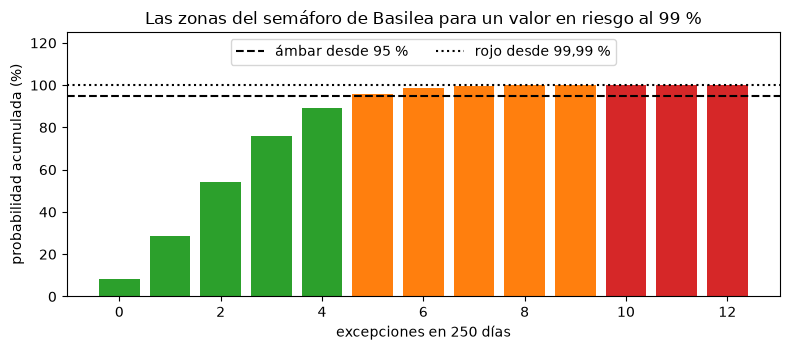

,excepciones,probabilidad acumulada (%),zona,multiplicador
4,4,89.2188,verde,1.50
5,5,95.8817,ámbar,1.70
9,9,99.9750,ámbar,1.92
10,10,99.9946,rojo,2.00


In [11]:
# El semáforo de Basilea para un valor en riesgo al 99 % en 250 días: la zona de la regulación, de 0 a 12 excepciones
rows = []
for k in range(13):
    days = np.zeros(250)
    days[:k] = 1
    result = basel_traffic_light(days)
    rows.append({"excepciones": k, "probabilidad acumulada (%)": round(result.metric, 4), "zona": result.light.value,
                 "multiplicador": result.extras["mar32_multiplier"]})
zones = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 3.6))
colours = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
ax.bar(zones["excepciones"], zones["probabilidad acumulada (%)"], color=[colours[z] for z in zones["zona"]])
ax.axhline(95, color="black", linestyle="--", label="ámbar desde 95 %")
ax.axhline(99.99, color="black", linestyle=":", label="rojo desde 99,99 %")
ax.set_ylim(0, 125)
ax.set_xlabel("excepciones en 250 días")
ax.set_ylabel("probabilidad acumulada (%)")
ax.set_title("Las zonas del semáforo de Basilea para un valor en riesgo al 99 %")
ax.legend(loc="upper center", ncol=2)
fig.tight_layout()
plt.show()
zones["zona"] = zones["zona"].map(LIGHT)
zones.iloc[[4, 5, 9, 10]]

Hasta 4 excepciones la probabilidad acumulada está bajo 95 por ciento (89,2188 en 4) y la zona es verde con un multiplicador de 1,50; en 5 llega a 95,8817 y la zona pasa a ámbar con un multiplicador de 1,70, y sigue ámbar hasta 9 (99,9750, multiplicador 1,92); en 10 llega a 99,9946 y la zona es roja con un multiplicador de 2,00. Aquí el color no es una elección de política: es la zona que el texto define para el conteo, y el resultado nombra su fuente. Las barras de 0 a 3 excepciones son verdes y quedan bajo las líneas. La figura muestra un caso en que los umbrales son regulación, y aun ahí el semáforo es la zona del texto para el número calculado, nunca un veredicto de que una institución cumple.

## Resultados

**Respuesta:** Con la política por defecto el motor encuentra la verdad: la muestra de desarrollo calibrada (100 incumplimientos, 111,2 esperados) es verde con un valor p de 0,863, y la muestra actual (207 incumplimientos, 138,1 esperados) es roja con un valor p de 6,047e-09. Si cambia solo la política, cambia el color y no el valor p: la política estricta vuelve ámbar la muestra correcta y la laxa vuelve ámbar la muestra equivocada.

- **El color es una lectura, no una propiedad.** Un semáforo significa algo solo junto con la política que lo produjo, y el `TestResult` lleva esa etiqueta por esta razón.
- **Los umbrales ausentes son visibles.** Una prueba sin umbral en la política, como el AUC, devuelve `sin evaluar`; nunca es verde en silencio.
- **La regla de redacción del producto.** Un semáforo de Contraste dice "bajo la política `riskvalidation-default 2026.10.1`, el valor p está bajo 0,01"; nunca dice que un modelo cumple o no cumple. Para las pruebas de crédito, las fuentes supervisoras que cita el motor (ECB 2019; BCBS Working Paper 14, 2005) no fijan umbrales, y las notas de fuente de los umbrales lo dicen.
- **La excepción.** Donde el texto regulatorio fija las zonas, como en el semáforo de contraste retrospectivo de Basilea (5 excepciones son ámbar y 10 son rojo), el motor calcula la zona de ese texto y nombra su fuente. Los temas 07 y 09 de este conjunto de notebooks muestran las pruebas de riesgo de mercado y de riesgo de tasa de interés.

Lo que este notebook no hace es elegir una política por ti: eso es trabajo de la función de riesgo de modelos de la institución.

## Resumen

- Una `Policy` son datos versionados que asocian el identificador de una prueba con un `Threshold` de tipo `p_value`, `upper_bad` o `lower_bad`; la política por defecto contiene 48 de ellos y las pruebas de crédito se colorean con 0,05 y 0,01.
- El mismo estadístico y el mismo valor p dan semáforos distintos bajo políticas distintas, y el resultado registra la etiqueta de la política y los puntos de corte.
- Una prueba sin umbral es `sin evaluar`, nunca verde.
- Para las pruebas de crédito, ninguna fuente supervisora fija umbrales, de modo que son política de una institución. Donde una regulación define zonas (MAR32.9, SRP31), el motor calcula la zona del texto y nombra su fuente.

**Qué probar a continuación.** Agrega un umbral para `disc.auc` a una política propia (tipo `lower_bad`) y repite el AUC del notebook 02 bajo ella. Después continúa con el notebook 04, que ejecuta una batería completa bajo una política.

## Referencias

- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk: definen las pruebas y no fijan umbrales de aprobación o fallo. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2), el intervalo de Jeffreys detrás de la prueba. https://doi.org/10.1214/ss/1009213286
- Este repositorio: `docs/design/SDD.md` (no objetivo 1: ningún semáforo es un veredicto de cumplimiento) y `docs/guides/02_validate-your-own-model.md`.
- BCBS, Basel Framework, MAR32 (enfoque de modelos internos: contraste retrospectivo y semáforo, MAR32.9). https://www.bis.org/basel_framework/chapter/MAR/32.htm
- BCBS, Basel Framework, SRP31 (riesgo de tasa de interés en la cartera de inversión, prueba de valores atípicos, SRP31.82 a SRP31.83). https://www.bis.org/basel_framework/chapter/SRP/31.htm